# 20 — Depth and representation learning

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–19, especially depth versus width for sawtooth functions (12), forward hooks (15), activations (16), Kaiming initialization (18) and Adam (19) |
| **You will learn** | How to look inside a trained network layer by layer; how a stack of layers gradually deforms the input space until the classes can be separated by a line; principal component analysis (PCA) as the best 2-D linear view of a wide layer; linear probes as a measurement tool for "how linearly decodable is the label here?"; what individual hidden units detect and how the second layer composes first-layer half-planes; how to compare shallow-wide and deep-narrow networks fairly (matched parameter counts, fixed budget, several seeds); counting linear regions along a line |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, about a minute in total (most of it in the width-versus-depth experiments and Exercise 4). No GPU section: every network here is tiny. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import copy
import math
import time

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_checkerboard, make_rings, make_spirals
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

## The motivating problem

Notebook 11 built a network by hand for XOR: the hidden layer mapped the four inputs to points that a single line could separate. Notebook 12 proved that depth *can* be exponentially more efficient than width, for very special sawtooth functions. Since then (notebooks 13–19) we have trained MLPs whose weights nobody chose by hand. Two questions remain open:

1. **What does each layer of a trained network actually compute?** Does the XOR picture — "hidden layers transform the data until a line suffices" — describe what gradient descent finds?
2. **In practice, not in theory, when does adding depth help, and when does it hurt?**

We answer the first by *looking*: we record each layer's output with forward hooks (notebook 15) and plot it, directly when it is 2-D and through PCA when it is wider, and we *measure* it with linear probes. We answer the second with controlled experiments: networks of different depths with the **same number of parameters**, trained with the same budget, over several seeds. The answers will be empirical, for small 2-D problems, and we will say so.

Notation as in the rest of Chapter 3: data $X$ of shape $(N, D)$, one example per row; layer $\ell$ computes the pre-activation $A^{(\ell)} = H^{(\ell-1)} W^{(\ell)\top} + \mathbf b^{(\ell)}$ and the activation $H^{(\ell)} = \varphi(A^{(\ell)})$, with $H^{(0)} = X$. We call $H^{(\ell)}$ the **representation** of the data at layer $\ell$: one row per example, one column per unit.

Every experiment below trains with the same full-batch loop (notebook 19 showed mini-batches; here the datasets are small enough that full batches are simpler and deterministic):

In [3]:
def train_full_batch(model, X, y, loss_fn=F.cross_entropy, steps=2000, lr=0.01):
    """Train `model` on (X, y) with full-batch Adam; return the final training loss (float)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        loss = loss_fn(model(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return loss.item()


def accuracy(model, X, y):
    """Fraction of rows of X whose arg-max logit equals the label."""
    with torch.no_grad():
        return (model(X).argmax(dim=1) == y).double().mean().item()

## 1. Watching representations form in two dimensions

A hidden layer with 16 units produces a 16-dimensional representation, which we cannot plot. So we design a network whose intermediate representations are **2-D on purpose**. It is a stack of **bottleneck blocks**, each mapping the plane to the plane:

$$\mathbf r^{(\ell)} = W_{\text{out}}^{(\ell)}\, \tanh\!\big(W_{\text{in}}^{(\ell)} \mathbf r^{(\ell-1)} + \mathbf b_{\text{in}}^{(\ell)}\big) + \mathbf b_{\text{out}}^{(\ell)}, \qquad \mathbf r^{(0)} = \mathbf x,$$

with $W_{\text{in}}^{(\ell)}$ of shape $(16, 2)$ and $W_{\text{out}}^{(\ell)}$ of shape $(2, 16)$. Inside each block there is a 16-unit hidden layer, but what the block passes on, $\mathbf r^{(\ell)}$, is a point in the plane. After $L = 4$ blocks, a final `nn.Linear(2, 2)` computes the two class logits. So the network is forced to "talk to itself" in 2-D, and we can draw every message.

We use tanh inside the blocks because it is smooth: each block then deforms the plane continuously, which is easy to follow by eye. Exercise 1 switches to ReLU, which folds and flattens the plane instead.

In [4]:
def bottleneck_block(hidden=16, act=nn.Tanh):
    """A map from the plane to the plane: Linear(2, hidden) -> act -> Linear(hidden, 2). (N, 2) -> (N, 2)."""
    return nn.Sequential(nn.Linear(2, hidden), act(), nn.Linear(hidden, 2))


def bottleneck_net(n_blocks=4, hidden=16, n_classes=2, act=nn.Tanh):
    """n_blocks plane-to-plane blocks followed by a linear classifier on the last 2-D representation."""
    return nn.Sequential(*[bottleneck_block(hidden, act) for _ in range(n_blocks)], nn.Linear(2, n_classes))


X_sp, y_sp = make_spirals(n=300, classes=2, seed=0)        # (600, 2), (600,): two arms, 1.5 turns
torch.manual_seed(0)
bnet = bottleneck_net()
start = time.perf_counter()
loss_b = train_full_batch(bnet, X_sp, y_sp, steps=2000, lr=0.01)
print(bnet)
print(f"final training loss {loss_b:.4f}, training accuracy {accuracy(bnet, X_sp, y_sp):.3f}"
      f"  ({time.perf_counter() - start:.1f} s)")

Sequential(
  (0): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=2, bias=True)
  )
  (1): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=2, bias=True)
  )
  (2): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=2, bias=True)
  )
  (3): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=2, bias=True)
  )
  (4): Linear(in_features=2, out_features=2, bias=True)
)
final training loss 0.0304, training accuracy 0.987  (2.4 s)


The network fits the two spiral arms. Now we record the output of every block. A **forward hook** (notebook 15) is a function `hook(module, inputs, output)` that PyTorch calls right after the module's `forward`. We store `output.detach().clone()`: `detach` so the stored tensor does not keep the autograd graph alive, and `clone` so that later in-place operations cannot change what we stored (Exercise 3 shows what goes wrong without it). We always remove the hooks afterwards.

In [5]:
def capture(model, modules, X):
    """Run model(X) once and return the outputs of the given submodules, in the given order."""
    store = {}
    handles = [m.register_forward_hook(lambda mod, inputs, output, i=i: store.__setitem__(i, output.detach().clone()))
               for i, m in enumerate(modules)]
    try:
        with torch.no_grad():
            model(X)
    finally:
        for h in handles:
            h.remove()
    return [store[i] for i in range(len(modules))]


reps_b = [X_sp] + capture(bnet, list(bnet)[:-1], X_sp)    # r^(0) = x, then r^(1), ..., r^(4): each (600, 2)
print([tuple(r.shape) for r in reps_b])

[(600, 2), (600, 2), (600, 2), (600, 2), (600, 2)]


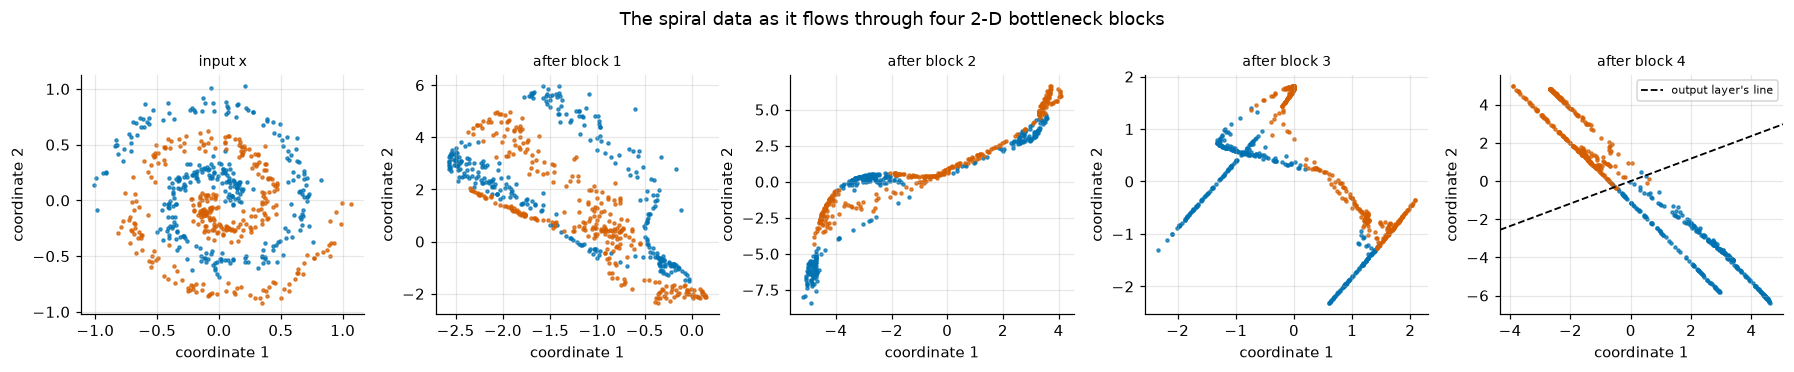

In [6]:
def plot_reps(reps, y, head=None, titles=None, suptitle=None):
    """One scatter plot per 2-D representation. If `head` (a Linear(2, 2)) is given, draw its decision line on the last."""
    fig, axes = plt.subplots(1, len(reps), figsize=(3.3 * len(reps), 3.4))
    for j, (ax, r) in enumerate(zip(axes, reps)):
        for k in torch.unique(y).tolist():
            ax.scatter(r[y == k, 0], r[y == k, 1], s=4, color=COLORS[k], alpha=0.7)
        ax.set_xlabel("coordinate 1")
        ax.set_ylabel("coordinate 2")
        ax.set_title(titles[j] if titles else ("input x" if j == 0 else f"after block {j}"), fontsize=9)
    if head is not None:
        ax = axes[-1]
        w = (head.weight[1] - head.weight[0]).detach()     # logit difference z_1 - z_0 = w · r + c
        c = (head.bias[1] - head.bias[0]).item()
        xs = torch.linspace(*ax.get_xlim(), 50)
        ax.set_autoscale_on(False)
        ax.plot(xs, -(w[0] * xs + c) / w[1], "k--", lw=1.2, label="output layer's line")
        ax.legend(fontsize=7)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


plot_reps(reps_b, y_sp, head=bnet[-1], suptitle="The spiral data as it flows through four 2-D bottleneck blocks")

Read the panels left to right. In the input the two arms are wound around each other; no line separates them. Block 1 stretches and bends the plane, but the arms are still interleaved. Block 2 squeezes almost all the points onto a thin curve: the arms now lie *along* that curve in alternating stretches, still interleaved, but laid out nearly one-dimensionally. Block 3 pulls the two colors apart into separate strands, and block 4 straightens them into two roughly parallel bands, so the output layer's straight line (dashed) separates them. The output layer is just a linear classifier (softmax regression, notebook 10) applied to $\mathbf r^{(4)}$: **all the nonlinear work is done before it**.

The axis ranges change from panel to panel: each block is free to rescale the plane, and only the relative arrangement of the points matters.

### The plane itself, warped block by block

The scatter plots show only where the data go. To see what each block does to the *whole* plane, we push a square grid of lines through the blocks, as notebook 02 did for a single matrix. Lines of constant $x_2$ are blue, lines of constant $x_1$ orange.

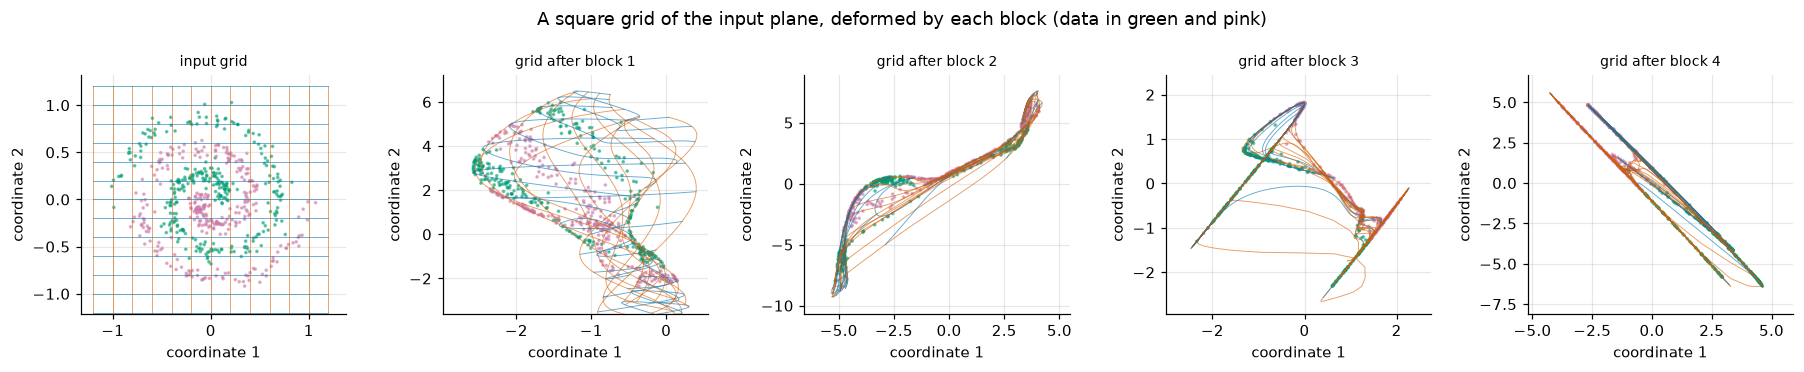

In [7]:
def warp_lines(model_blocks, lim=1.2, n_lines=13, n_pts=300):
    """Images of a grid of lines under successive blocks. Returns a list (one per stage) of lists of (n_pts, 2) tensors."""
    ts = torch.linspace(-lim, lim, n_pts)
    lines = []
    for level in torch.linspace(-lim, lim, n_lines):
        lines.append(torch.stack([ts, torch.full_like(ts, level.item())], dim=1))   # horizontal: x2 = level
        lines.append(torch.stack([torch.full_like(ts, level.item()), ts], dim=1))   # vertical:   x1 = level
    stages = [lines]
    with torch.no_grad():
        for block in model_blocks:
            lines = [block(line) for line in lines]
            stages.append(lines)
    return stages


stages = warp_lines(list(bnet)[:-1])
fig, axes = plt.subplots(1, len(stages), figsize=(3.3 * len(stages), 3.4))
for j, (ax, lines, r) in enumerate(zip(axes, stages, reps_b)):
    for i, line in enumerate(lines):
        ax.plot(line[:, 0], line[:, 1], color=COLORS[0] if i % 2 == 0 else COLORS[1], lw=0.6, alpha=0.6)
    ax.scatter(r[:, 0], r[:, 1], s=2, c=[COLORS[2] if t == 0 else COLORS[3] for t in y_sp.tolist()], alpha=0.5)
    lo, hi = r.min(0).values, r.max(0).values
    pad = 0.15 * (hi - lo)
    ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0])
    ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.set_xlabel("coordinate 1")
    ax.set_ylabel("coordinate 2")
    ax.set_title("input grid" if j == 0 else f"grid after block {j}", fontsize=9)
fig.suptitle("A square grid of the input plane, deformed by each block (data in green and pink)")
plt.tight_layout()
plt.show()

The grid lines stay **continuous** (a tanh block never tears the plane) but they no longer stay straight or evenly spaced, as they did under a single matrix in notebook 02. After block 1 some grid lines already cross each other: because each block ends with a map from 16 dimensions down to 2, it can fold the plane smoothly onto itself. From block 2 on, most of the square is squeezed into thin strips, while the part where the data live is stretched out. The data (green and pink) ride along: the network has learned a deformation of the plane in which the two arms end up on opposite sides of a line. This is the picture to keep in mind for "representation learning": **each layer re-describes the data, and training chooses the re-descriptions that make the final linear readout easy**.

Where the intuition stops being accurate: real networks have wide layers, so the deformation happens in many dimensions at once, and nothing forces any single intermediate layer to be "half-untangled". Section 2 measures this for a wide network.

### Checkpoint 1.1

Use `capture` to record the **16-unit tanh layer inside block 2** (the module `bnet[1][1]`) for the spiral data. Store it in `hidden_b2`. Predict its shape and the range of its values before running.

<details>
<summary><b>💡 Hint</b></summary>

`capture(bnet, [bnet[1][1]], X_sp)` returns a list with one tensor. Since it is a tanh output, every entry lies strictly between $-1$ and $1$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(tuple(hidden_b2.shape), f"min {hidden_b2.min().item():.3f}  max {hidden_b2.max().item():.3f}")

In [ ]:
check_shape(hidden_b2, (600, 16), "hidden_b2")
with torch.no_grad():
    _expected = torch.tanh(bnet[1][0](bnet[0](X_sp)))
check_close(hidden_b2, _expected, "hidden_b2")
check(hidden_b2.grad_fn is None, "store a detached tensor")
passed("Checkpoint 1.1")

### Checkpoint 1.2

The output layer `bnet[-1]` computes logits $z_k = \mathbf u_k \cdot \mathbf r^{(4)} + c_k$ for $k = 0, 1$. For two classes, the prediction is class 1 exactly when $z_1 - z_0 > 0$, i.e. on one side of the line $(\mathbf u_1 - \mathbf u_0) \cdot \mathbf r + (c_1 - c_0) = 0$. From the weights of `bnet[-1]` and the captured `reps_b[4]` alone, compute `pred_from_line`, a `(600,)` integer tensor of predicted classes, without calling the network.

<details>
<summary><b>💡 Hint</b></summary>

`w = bnet[-1].weight[1] - bnet[-1].weight[0]` (shape `(2,)`), `c = bnet[-1].bias[1] - bnet[-1].bias[0]`. Then `(reps_b[4] @ w + c > 0).long()`. Wrap it in `torch.no_grad()` or use `.detach()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(pred_from_line, (600,), "pred_from_line")
with torch.no_grad():
    _net_pred = bnet(X_sp).argmax(dim=1)
check(bool((pred_from_line == _net_pred).all()), "the line rule should reproduce every prediction of the network")
passed("Checkpoint 1.2")

## 2. Wider layers: PCA and linear probes

Now an ordinary MLP: 2 inputs, **four hidden layers of 32 ReLU units**, 3 outputs, on three interleaved spiral arms. We initialize with Kaiming/He (notebook 18): weights $\mathcal N(0, 2/n_{\text{in}})$ and zero biases in the ReLU layers, and $\mathcal N(0, 1/n_{\text{in}})$ for the output layer, which has no ReLU after it. We also draw a second, independent sample from the same distribution as a **validation set**: data the network never trains on, so that a measurement there cannot be explained by memorization (notebook 22 treats this properly).

In [12]:
def mlp(d_in, width, depth, d_out):
    """`depth` hidden ReLU layers of `width` units, Kaiming-normal weights and zero biases."""
    layers, d = [], d_in
    for _ in range(depth):
        lin = nn.Linear(d, width)
        nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")      # variance 2 / fan_in
        nn.init.zeros_(lin.bias)
        layers += [lin, nn.ReLU()]
        d = width
    out = nn.Linear(d, d_out)
    nn.init.kaiming_normal_(out.weight, nonlinearity="linear")        # variance 1 / fan_in
    nn.init.zeros_(out.bias)
    return nn.Sequential(*layers, out)


X3, y3 = make_spirals(n=300, classes=3, seed=0)         # (900, 2) training set
X3v, y3v = make_spirals(n=300, classes=3, seed=1)       # (900, 2) validation set, same distribution
torch.manual_seed(0)
wide = mlp(2, 32, 4, 3)
wide_init = copy.deepcopy(wide)                         # an untrained copy, used as a control below
loss_w = train_full_batch(wide, X3, y3, steps=1500, lr=0.01)
print(f"training loss {loss_w:.4f}   training accuracy {accuracy(wide, X3, y3):.3f}   "
      f"validation accuracy {accuracy(wide, X3v, y3v):.3f}")


def hidden_reps(model, X):
    """[X, H^(1), ..., H^(L)]: the input and the output of every ReLU of an `mlp`."""
    return [X] + capture(model, [m for m in model if isinstance(m, nn.ReLU)], X)


reps_w = hidden_reps(wide, X3)
print("representation shapes:", [tuple(r.shape) for r in reps_w])

training loss 0.0334   training accuracy 0.986   validation accuracy 0.936
representation shapes: [(900, 2), (900, 32), (900, 32), (900, 32), (900, 32)]


### PCA: the best 2-D linear view

Each $H^{(\ell)}$ is a cloud of 900 points in $\mathbb R^{32}$. To look at it we project onto the **two directions along which the cloud varies most**. This is **principal component analysis** (Pearson 1901; Hotelling 1933).

1. **Center:** $H_c = H - \bar{\mathbf h}$, subtracting the mean row (shape $(1, 32)$) from every row.
2. **Singular value decomposition:** $H_c = U S V^\top$, with $U$ of shape $(N, r)$ and $V$ of shape $(32, r)$ having orthonormal columns and $S = \operatorname{diag}(s_1 \ge s_2 \ge \dots \ge 0)$. `torch.linalg.svd(Hc, full_matrices=False)` returns $U$, the vector $(s_1, s_2, \dots)$ and $V^\top$.
3. **Project:** the coordinates of the points in the plane spanned by the first two columns of $V$ are $H_c V_{:, :2} = U_{:, :2}\, \operatorname{diag}(s_1, s_2)$.

The variance of the data along the unit direction $\mathbf v_k$ is $\frac1N\|H_c \mathbf v_k\|^2 = s_k^2/N$, and the total variance (summed over all 32 coordinates) is $\frac1N\|H_c\|_F^2 = \frac1N\sum_j s_j^2$. So the **explained-variance ratio** of component $k$ is

$$\rho_k = \frac{s_k^2}{\sum_j s_j^2}.$$

The key fact, stated without proof (it follows from the Eckart–Young theorem, 1936): **no other 2-D linear projection keeps more variance** than the first two principal directions, and equivalently none has a smaller squared reconstruction error. We verify it numerically below rather than prove it.

In [13]:
def pca_2d(H):
    """Project the rows of H (N, d) onto their top two principal directions.

    Returns (coords, ratio): coords (N, 2) and the explained-variance ratios of the two components, (2,).
    """
    Hc = H - H.mean(dim=0, keepdim=True)                          # (N, d) centered
    U, s, Vh = torch.linalg.svd(Hc, full_matrices=False)          # U (N, r), s (r,), Vh (r, d)
    coords = Hc @ Vh[:2].T                                        # (N, 2) = U[:, :2] * s[:2]
    ratio = s[:2] ** 2 / (s**2).sum()
    return coords, ratio


H4 = reps_w[4]
coords4, ratio4 = pca_2d(H4)
H4c = H4 - H4.mean(0, keepdim=True)
total_var = (H4c**2).sum(dim=1).mean()
pca_var = (coords4**2).sum(dim=1).mean()
print(f"layer 4: explained-variance ratio of PC1, PC2 = {ratio4[0]:.3f}, {ratio4[1]:.3f};"
      f" variance kept {pca_var / total_var:.3f} (= {ratio4.sum():.3f})")

# Compare with 2,000 random 2-D orthonormal projections.
gen = torch.Generator().manual_seed(0)
kept = []
for _ in range(2000):
    Q, _ = torch.linalg.qr(torch.randn(H4.shape[1], 2, generator=gen))    # (32, 2), orthonormal columns
    kept.append(((H4c @ Q) ** 2).sum(dim=1).mean() / total_var)
kept = torch.stack(kept)
print(f"random projections: best {kept.max():.3f}, median {kept.median():.3f} of the variance")
check(bool((kept <= ratio4.sum() + 1e-6).all()), "no random projection should beat PCA")

layer 4: explained-variance ratio of PC1, PC2 = 0.450, 0.180; variance kept 0.630 (= 0.630)
random projections: best 0.298, median 0.056 of the variance


The printed numbers confirm the two claims: the variance kept by the projection equals $\rho_1 + \rho_2$, and none of 2,000 random orthonormal projections keeps more than PCA does (the best random one comes close only by chance alignment with the top directions).

### Checkpoint 2.1

By hand first. A centered matrix has singular values $(4, 2, 1, 1)$. Store in `rho_by_hand` (a tensor of shape `(2,)`) the explained-variance ratios of its first two principal components, and in `kept_by_hand` (a float) the fraction of variance a 2-D PCA projection keeps.

<details>
<summary><b>💡 Hint</b></summary>

Square the singular values: $16, 4, 1, 1$, total $22$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(rho_by_hand, (2,), "rho_by_hand")
check_close(rho_by_hand.double(), torch.tensor([16 / 22, 4 / 22], dtype=torch.float64), "rho_by_hand")
check_close(kept_by_hand, 20 / 22, "kept_by_hand")
passed("Checkpoint 2.1")

Now the PCA view of every layer of the trained network:

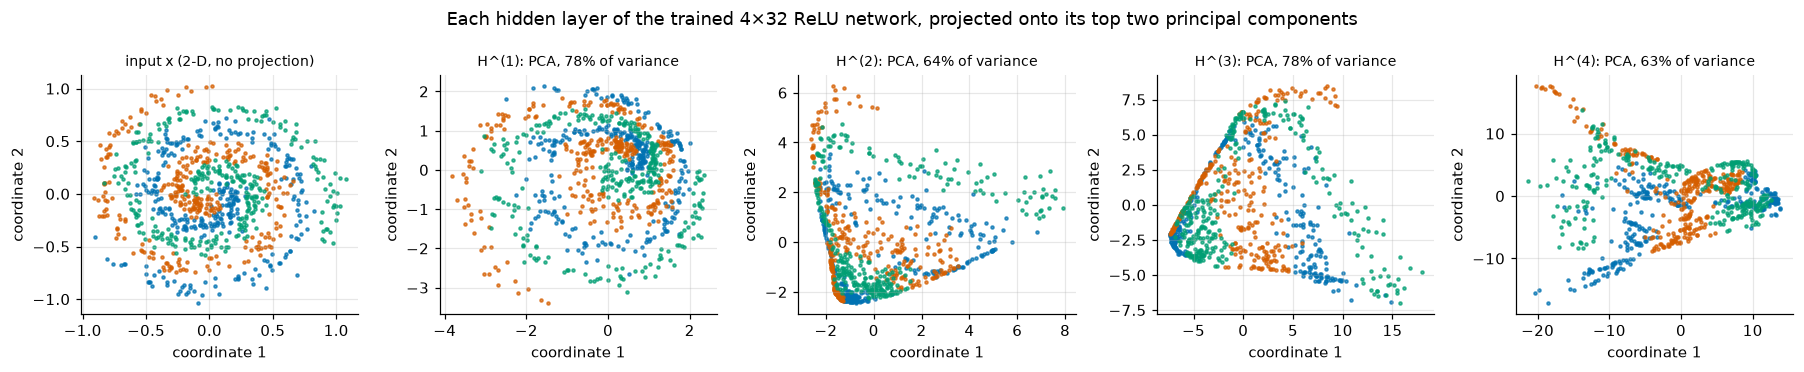

In [16]:
pcs = [pca_2d(r) for r in reps_w]
plot_reps([c for c, _ in pcs], y3,
          titles=["input x (2-D, no projection)"] + [f"H^({l}): PCA, {rt.sum():.0%} of variance" for l, (_, rt) in enumerate(pcs) if l > 0],
          suptitle="Each hidden layer of the trained 4×32 ReLU network, projected onto its top two principal components")

Two things to notice. The three arms (blue, orange, green) are wound together in the input and still mixed in the projection of $H^{(1)}$, which looks like a distorted copy of the input. From $H^{(2)}$ on, each class gathers into its own elongated streaks, and in $H^{(3)}$ and $H^{(4)}$ the streaks of different colors are mostly side by side rather than wound around each other. But they still overlap in places in these 2-D pictures. Each projection keeps only 63–78% of the variance (the titles), so a PCA picture can **hide** structure that lives in the other 30 dimensions: classes that overlap in the projection may be separable in the full space. We need a measurement that uses all the dimensions.

### Linear probes

A **linear probe** answers the question: *how well can a linear classifier read the label off this layer?* We freeze the network, compute $H^{(\ell)}$ for every example, and train a softmax regression (notebook 10) on those features alone. Its accuracy on the validation set is the probe accuracy of layer $\ell$ (Alain and Bengio, 2016, proposed probes as a tool for exactly this).

Details that matter:

- The probe is trained separately; **the network's weights do not change**.
- We standardize each feature with the training mean and standard deviation (notebook 06) and add a tiny L2 penalty, $10^{-4}\|W\|^2$, so that the optimum exists even when the features are separable (notebook 09).
- We fit it with L-BFGS (`torch.optim.LBFGS`), a quasi-Newton method that converges in a few hundred iterations on this convex problem. Notebook 09 used it as a reference solver.
- We report **validation** accuracy: a probe on 32 features can fit 900 training points better than chance even if the features carry no useful structure.

In [17]:
def probe_accuracy(H_train, y_train, H_val, y_val, n_classes, l2=1e-4, max_iter=300):
    """Train a softmax-regression probe on frozen features; return (train accuracy, validation accuracy)."""
    mu, sd = H_train.mean(0), H_train.std(0) + 1e-6               # (d,) each; +1e-6 guards dead (constant) units
    Ztr, Zva = (H_train - mu) / sd, (H_val - mu) / sd
    W = torch.zeros(H_train.shape[1], n_classes, requires_grad=True)
    b = torch.zeros(n_classes, requires_grad=True)
    opt = torch.optim.LBFGS([W, b], max_iter=max_iter, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(Ztr @ W + b, y_train) + l2 * (W**2).sum()
        loss.backward()
        return loss

    opt.step(closure)
    with torch.no_grad():
        return tuple(((Z @ W + b).argmax(1) == t).double().mean().item() for Z, t in [(Ztr, y_train), (Zva, y_val)])


def probe_all_layers(model, reps_fn, X, y, Xv, yv, n_classes):
    """Validation probe accuracy for every representation returned by reps_fn(model, X)."""
    return [probe_accuracy(a, y, b, yv, n_classes)[1] for a, b in zip(reps_fn(model, X), reps_fn(model, Xv))]


probe_trained = probe_all_layers(wide, hidden_reps, X3, y3, X3v, y3v, 3)
probe_random = probe_all_layers(wide_init, hidden_reps, X3, y3, X3v, y3v, 3)
print("layer:                ", "   ".join(f"{l:5d}" for l in range(5)))
print("probe, trained network", "   ".join(f"{a:.3f}" for a in probe_trained))
print("probe, same net at init", "  ".join(f"{a:.3f}" for a in probe_random))

layer:                     0       1       2       3       4
probe, trained network 0.461   0.534   0.871   0.916   0.941
probe, same net at init 0.461  0.430  0.418  0.414  0.406


The second row is a **control**: the same architecture before training, i.e. random ReLU features of the same widths. It tells us how much of the probe accuracy comes merely from having 32 random nonlinear features instead of 2 inputs.

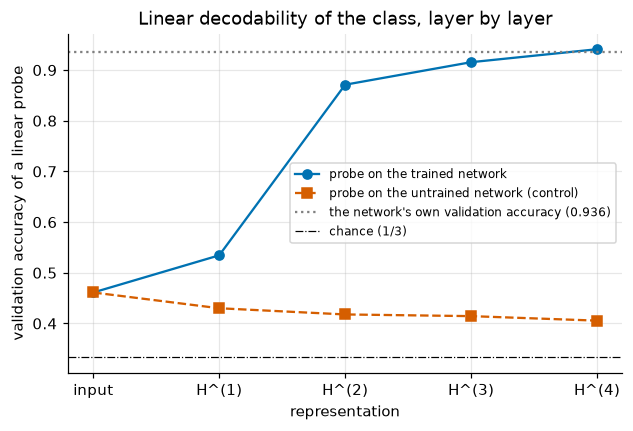

In [18]:
own_val = accuracy(wide, X3v, y3v)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(5), probe_trained, "o-", label="probe on the trained network")
ax.plot(range(5), probe_random, "s--", label="probe on the untrained network (control)")
ax.axhline(own_val, color="gray", ls=":", label=f"the network's own validation accuracy ({own_val:.3f})")
ax.axhline(1 / 3, color="k", lw=0.8, ls="-.", label="chance (1/3)")
ax.set_xticks(range(5), ["input", "H^(1)", "H^(2)", "H^(3)", "H^(4)"])
ax.set_xlabel("representation")
ax.set_ylabel("validation accuracy of a linear probe")
ax.set_title("Linear decodability of the class, layer by layer")
ax.legend(fontsize=8)
plt.show()

In the trained network, linear decodability rises with depth: 0.46 at the input (chance is 1/3), 0.53 at $H^{(1)}$, then a large jump to 0.87 at $H^{(2)}$ and further gains to 0.92 and 0.94 at $H^{(3)}$ and $H^{(4)}$, where the probe slightly exceeds the network's own validation accuracy (the output layer *is* a linear readout of $H^{(4)}$, so the probe should at least roughly match it). The untrained control does not improve on the input at all: it drifts from 0.46 down to about 0.41. Random ReLU features of this size do not untangle spirals. **The separability is learned, not a side effect of width.** The PCA pictures above looked much less separated than 0.94; this is the hidden-dimensions caveat in action.

What a probe does *not* tell us: whether the network *uses* the information it finds (a probe can decode things the next layer ignores), and anything about nonlinear decodability — a layer where the probe fails may still contain the label in a form a nonlinear classifier could read. Probes measure; they do not explain.

The same probe on the 2-D bottleneck representations of Section 1 (with a fresh validation sample of the spirals) puts numbers on what we saw:

In [19]:
X_spv, y_spv = make_spirals(n=300, classes=2, seed=1)


def bottleneck_reps(model, X):
    """[x, r^(1), ..., r^(L)] for a bottleneck_net."""
    return [X] + capture(model, list(model)[:-1], X)


probe_b = probe_all_layers(bnet, bottleneck_reps, X_sp, y_sp, X_spv, y_spv, 2)
print("bottleneck network, validation probe accuracy per stage:", [f"{a:.3f}" for a in probe_b])

bottleneck network, validation probe accuracy per stage: ['0.648', '0.603', '0.492', '0.962', '0.962']


In 2-D a linear probe is just "the best line", and the numbers follow the pictures of Section 1: the arms are far from linearly separable at the input (0.65) and after block 1 (0.60). After block 2 the probe is even at chance (0.49), although the network is one step closer to its goal: the arms lie along a curve in alternating stretches, which no single line can split. After blocks 3 and 4 the probe jumps to 0.96. So **linear separability need not increase at every layer.** Nothing in the loss asks the intermediate representations to be separable; only the last one is read by a linear layer.

### Checkpoint 2.2

A linear map cannot make data more linearly separable: any linear classifier applied to $A^{(2)} = H^{(1)} W^{(2)\top} + \mathbf b^{(2)}$ is *also* a linear classifier applied to $H^{(1)}$ (compose the two affine maps, notebook 02). Only the ReLU can help. Test this on the trained network: capture the **pre-activation** $A^{(2)}$ (the output of the module `wide[2]`) for the training and validation sets, and store its validation probe accuracy in `probe_A2`. Compare with `probe_trained[1]` ($H^{(1)}$) and `probe_trained[2]` ($H^{(2)}$).

<details>
<summary><b>💡 Hint</b></summary>

`A2_train = capture(wide, [wide[2]], X3)[0]`, the same for `X3v`, then `probe_accuracy(A2_train, y3, A2_val, y3v, 3)[1]`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"probe on H^(1): {probe_trained[1]:.3f}   on A^(2): {probe_A2:.3f}   on H^(2) = relu(A^(2)): {probe_trained[2]:.3f}")

In [ ]:
_A2t, _A2v = capture(wide, [wide[2]], X3)[0], capture(wide, [wide[2]], X3v)[0]
check_close(probe_A2, probe_accuracy(_A2t, y3, _A2v, y3v, 3)[1], "probe_A2", atol=1e-3)
check(probe_A2 <= probe_trained[1] + 0.03, "a linear map of H^(1) should not be much more linearly decodable than H^(1)")
passed("Checkpoint 2.2")

The pre-activation $A^{(2)}$ is no more decodable than $H^{(1)}$; here it is even a little less (0.47 against 0.53), because the probe's standardization and penalty are not invariant to linear maps, and fitting and validation are on different samples. The jump to 0.87 at $H^{(2)}$ happens **at the ReLU**. Each layer's matrix chooses *which* directions to bend; the nonlinearity does the bending.

## 3. Hidden units as feature detectors

The pictures so far showed whole layers. Now single units. We train a small network, 2 inputs → 8 → 8 → 2 classes, on a $3 \times 3$ checkerboard: a target made of square tiles, so we can hope to see tile-shaped features.

In [22]:
X_cb, y_cb = make_checkerboard(n=1000, tiles=3, seed=0)        # (1000, 2) on [-1, 1]^2
torch.manual_seed(0)
small = mlp(2, 8, 2, 2)
loss_s = train_full_batch(small, X_cb, y_cb, steps=3000, lr=0.01)
print(f"training loss {loss_s:.4f}, training accuracy {accuracy(small, X_cb, y_cb):.3f}")

training loss 0.0033, training accuracy 1.000


**First-layer units.** Unit $k$ of layer 1 computes $\operatorname{relu}(\mathbf w_k \cdot \mathbf x + b_k)$. It is zero on one side of the line $\mathbf w_k \cdot \mathbf x + b_k = 0$ and grows linearly on the other, the side that $\mathbf w_k$ points to (notebook 07's geometry). So each first-layer unit is a **half-plane detector**, graded by distance from its line. We draw the 8 lines over the decision regions, with an arrow (length 0.25) from each line toward the side where the unit is on.

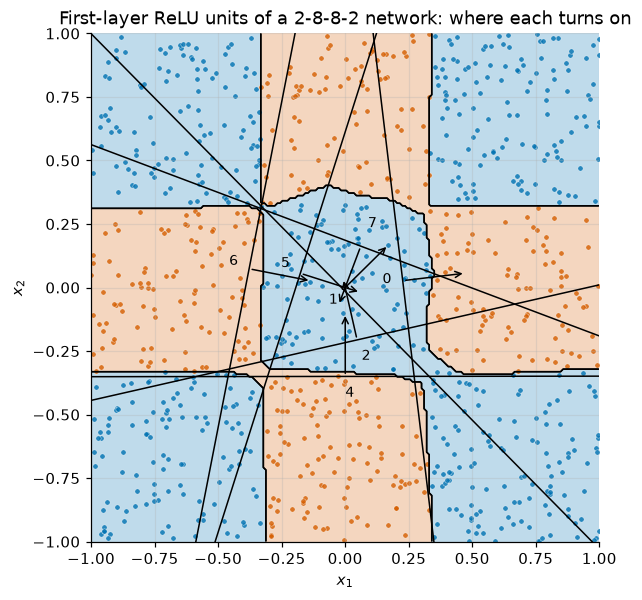

In [23]:
W1, b1 = small[0].weight.detach(), small[0].bias.detach()          # (8, 2), (8,)
fig, ax = plt.subplots(figsize=(6, 6))
plot_decision_boundary(lambda P: small(P).argmax(1), X_cb, y_cb, ax=ax, padding=0.0,
                       title="First-layer ReLU units of a 2-8-8-2 network: where each turns on")
g = torch.linspace(-1, 1, 100)
for k in range(8):
    w, b = W1[k], b1[k]
    if w[1].abs() > w[0].abs():          # draw as x2 = f(x1)
        ax.plot(g, -(w[0] * g + b) / w[1], color="k", lw=1)
    else:                                # nearly vertical: draw as x1 = f(x2)
        ax.plot(-(w[1] * g + b) / w[0], g, color="k", lw=1)
    foot = -b * w / (w @ w)                              # the point of the line closest to the origin
    if foot.abs().max() < 1:
        d = 0.25 * w / w.norm()
        ax.annotate("", xy=(foot + d).tolist(), xytext=foot.tolist(), arrowprops=dict(arrowstyle="->", color="k"))
        ax.annotate(str(k), (foot - 0.08 * w / w.norm()).tolist(), fontsize=9)
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
plt.show()

The decision regions have almost straight, axis-parallel edges at $x_1, x_2 = \pm\tfrac13$, but **the first-layer lines mostly do not**. Only a few lines lie close to a tile edge; most cut diagonally across the square, and several pass near the center. No single first-layer unit draws a tile edge. The straight edges come from *combinations* of slanted ramps, formed by the next layer. So reading a network one unit at a time has limits: the useful features can be distributed over several units.

**Second-layer units.** Unit $j$ of layer 2 computes $\operatorname{relu}\big(\sum_k W^{(2)}_{jk}\, \operatorname{relu}(\mathbf w_k \cdot \mathbf x + b_k) + b^{(2)}_j\big)$. Inside each cell of the arrangement of first-layer lines, the set of active first-layer units is fixed, so the inner sum is an affine function of $\mathbf x$. Hence the second-layer pre-activation is **piecewise linear** over those cells, and the unit is on where it is positive: a region whose boundary is a polygonal curve, with corners on first-layer lines. This is the ReLU, graded version of notebook 11, where a second layer of step units ANDed half-planes into polygons.

We draw the activation of every unit over the square, top row layer 1, bottom row layer 2, with the 8 first-layer lines in white.

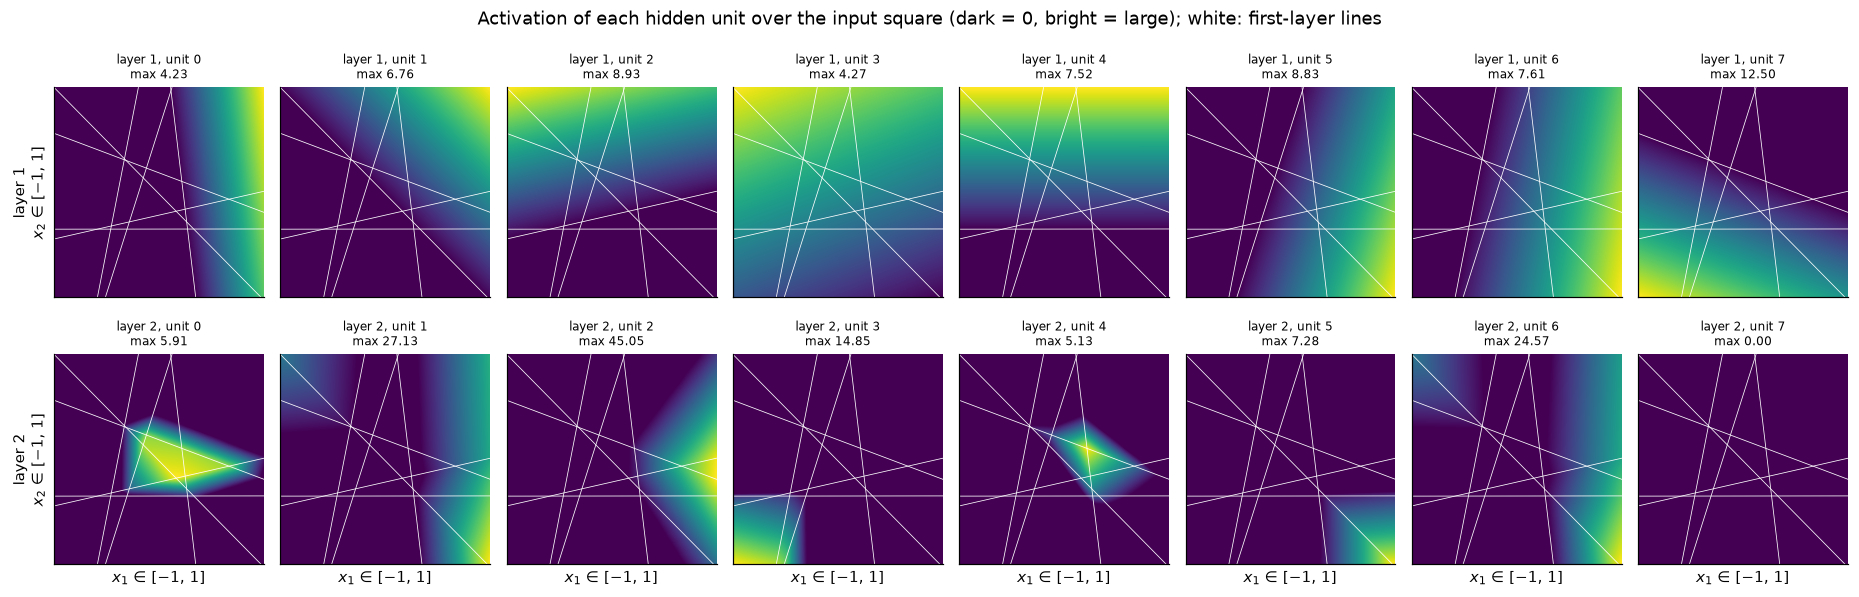

second-layer units that are zero everywhere on the square: [7]


In [24]:
res = 200
gx = torch.linspace(-1, 1, res)
G1, G2 = torch.meshgrid(gx, gx, indexing="xy")
P = torch.stack([G1.reshape(-1), G2.reshape(-1)], dim=1)            # (40000, 2) grid points
H1g, H2g = capture(small, [small[1], small[3]], P)                  # (40000, 8) each

fig, axes = plt.subplots(2, 8, figsize=(17, 5.6))
for r, Hg in enumerate([H1g, H2g]):
    for j in range(8):
        ax = axes[r, j]
        ax.imshow(Hg[:, j].reshape(res, res), origin="lower", extent=[-1, 1, -1, 1], cmap="viridis")
        for k in range(8):
            w, b = W1[k], b1[k]
            if w[1].abs() > w[0].abs():
                ax.plot(gx, -(w[0] * gx + b) / w[1], color="white", lw=0.5)
            else:
                ax.plot(-(w[1] * gx + b) / w[0], gx, color="white", lw=0.5)
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1, 1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"layer {r + 1}, unit {j}\nmax {Hg[:, j].max():.2f}", fontsize=8)
    axes[r, 0].set_ylabel(f"layer {r + 1}\n$x_2$ ∈ [−1, 1]")
for ax in axes[1]:
    ax.set_xlabel("$x_1$ ∈ [−1, 1]")
fig.suptitle("Activation of each hidden unit over the input square (dark = 0, bright = large); white: first-layer lines")
plt.tight_layout()
plt.show()

dead2 = [j for j in range(8) if H2g[:, j].max() == 0]
print("second-layer units that are zero everywhere on the square:", dead2)

The top row shows ramps: each first-layer unit is dark on one side of its own line and brightens linearly on the other. The bottom row is different in kind. Several second-layer units light up only in a **bounded, polygonal patch**: units 0 and 4 in polygons around the center tile, units 3 and 5 in the lower-left and lower-right corner tiles. The edges of these patches run along pieces of the white first-layer lines. A single first-layer unit can never do this (its active set is always a half-plane). The second layer **composes** half-planes into localized features, and the output layer then adds these features up into the checkerboard. Unit 7 of layer 2 is zero everywhere on the square. It is a dead ReLU (notebook 16) and contributes nothing to this network.

### Checkpoint 3.1

$n$ lines in general position (no two parallel, no three through one point) cut the plane into $1 + n + \binom n2$ regions: each new line $m$ crosses the $m - 1$ earlier ones, is split into $m$ pieces, and each piece divides one region in two. Store in `max_cells_8` the maximum number of regions for the 8 first-layer lines, and in `cells_seen` the number of **distinct activation patterns** of layer 1 (which units are on) over the grid `P`, i.e. the number of cells of the arrangement that intersect the square. Predict which is larger.

<details>
<summary><b>💡 Hint</b></summary>

`1 + 8 + 8 * 7 // 2`. For the patterns: `(H1g > 0)` is a `(40000, 8)` boolean tensor; `torch.unique(..., dim=0)` keeps its distinct rows.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"at most {max_cells_8} regions in the whole plane; {cells_seen} distinct layer-1 patterns inside the square")

In [ ]:
check(max_cells_8 == 37, "1 + n + n(n-1)/2 with n = 8")
check(cells_seen == torch.unique(H1g > 0, dim=0).shape[0], "count distinct rows of (H1g > 0)")
check(cells_seen <= max_cells_8, "cannot see more cells than exist")
passed("Checkpoint 3.1")

Fewer cells are visible than the maximum, because some intersections of lines fall outside the square. Within each visible cell the whole network is affine; the second layer adds its own kinks inside these cells, so the network's final linear pieces are finer still. Section 5 counts such pieces.

## 4. Width versus depth at matched parameter counts

Notebook 12 showed that depth can be exponentially more efficient *for representing* certain functions. Whether gradient descent *finds* those efficient deep solutions is a different question, which only experiments can answer. To compare depths fairly we fix what the networks are allowed to spend:

- **the same number of parameters** (a deeper network must be narrower);
- **the same training budget**: the same optimizer (Adam), learning rate and number of steps;
- **the same initialization rule** (Kaiming, so that deep ReLU nets start with well-scaled activations, notebook 18);
- **several seeds**, because one run of a small network can be lucky or unlucky (notebook 26 develops this into proper statistics).

For an MLP with input dimension $d$, $L$ hidden layers of width $w$, and $o$ outputs, the parameter count is

$$P(w, L) = \underbrace{(d + 1) w}_{\text{first layer}} + \underbrace{(L - 1)(w + 1) w}_{\text{hidden-to-hidden}} + \underbrace{(w + 1) o}_{\text{output}}.$$

It grows like $L w^2$, so at fixed $P$ the width shrinks like $1/\sqrt{L}$ once $L \ge 2$, while a single hidden layer can be very wide ($P$ is linear in $w$ when $L = 1$).

### Checkpoint 4.1

Implement `mlp_param_count(d_in, width, depth, d_out)` from the formula.

<details>
<summary><b>💡 Hint</b></summary>

Three terms: `(d_in + 1) * width`, `(depth - 1) * (width + 1) * width`, `(width + 1) * d_out`.

</details>

In [ ]:
def mlp_param_count(d_in, width, depth, d_out):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
for _args in [(2, 32, 4, 3), (1, 7, 6, 1), (2, 200, 1, 2), (5, 3, 2, 4)]:
    _n = sum(p.numel() for p in mlp(*_args).parameters())
    check(mlp_param_count(*_args) == _n, f"mlp_param_count{_args} = {mlp_param_count(*_args)}, but the model has {_n}")
passed("Checkpoint 4.1")

Teaching cells must not depend on an exercise, so the experiments use their own copy of the formula, plus a helper that picks the width whose count is closest to a budget:

In [29]:
def param_count(d_in, width, depth, d_out):
    return (d_in + 1) * width + (depth - 1) * (width + 1) * width + (width + 1) * d_out


def width_for_budget(budget, d_in, depth, d_out):
    """The width w whose parameter count is closest to `budget`."""
    return min(range(1, 5000), key=lambda w: abs(param_count(d_in, w, depth, d_out) - budget))


DEPTHS = [1, 2, 3, 4, 6]
for depth in DEPTHS:
    w = width_for_budget(1000, 2, depth, 2)
    print(f"depth {depth}: width {w:3d}, {param_count(2, w, depth, 2)} parameters")

depth 1: width 200, 1002 parameters
depth 2: width  29, 1017 parameters
depth 3: width  21, 1031 parameters
depth 4: width  17, 1005 parameters
depth 6: width  13, 977 parameters


### Task A: spirals with many turns

Two spiral arms with 3 full turns each (twice as many as before) and little noise, 500 points per arm, plus a validation sample of the same size. The boundary between the arms winds around the origin six times: a target with a lot of repeated structure. Budget: about 1,000 parameters; Adam with learning rate $3 \cdot 10^{-3}$ for 2,000 full-batch steps; seeds 0, 1, 2. We keep every trained model, and an untrained copy of it, for Section 5.

In [30]:
XA, yA = make_spirals(n=500, classes=2, turns=3, noise=0.02, seed=0)       # (1000, 2)
XAv, yAv = make_spirals(n=500, classes=2, turns=3, noise=0.02, seed=1)
SEEDS = [0, 1, 2]

start = time.perf_counter()
models_A, results_A = {}, {}
for depth in DEPTHS:
    width = width_for_budget(1000, 2, depth, 2)
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = mlp(2, width, depth, 2)
        init_copy = copy.deepcopy(model)
        train_loss = train_full_batch(model, XA, yA, steps=2000, lr=3e-3)
        models_A[depth, seed] = (init_copy, model)
        results_A[depth, seed] = (train_loss, accuracy(model, XAv, yAv))
print(f"15 runs in {time.perf_counter() - start:.0f} s\n")

print("depth  width  params   train loss (3 seeds)        validation accuracy (3 seeds)     mean ± std")
for depth in DEPTHS:
    width = width_for_budget(1000, 2, depth, 2)
    losses = [results_A[depth, s][0] for s in SEEDS]
    accs = torch.tensor([results_A[depth, s][1] for s in SEEDS])
    print(f"{depth:5d}  {width:5d}  {param_count(2, width, depth, 2):6d}   "
          + "  ".join(f"{l:.3f}" for l in losses) + "         "
          + "  ".join(f"{a:.3f}" for a in accs.tolist())
          + f"        {accs.mean():.3f} ± {accs.std():.3f}")

15 runs in 20 s

depth  width  params   train loss (3 seeds)        validation accuracy (3 seeds)     mean ± std
    1    200    1002   0.597  0.588  0.558         0.636  0.579  0.603        0.606 ± 0.029
    2     29    1017   0.100  0.143  0.316         0.927  0.867  0.759        0.851 ± 0.085
    3     21    1031   0.001  0.000  0.017         0.994  0.988  0.963        0.982 ± 0.016
    4     17    1005   0.001  0.000  0.000         0.985  0.983  0.980        0.983 ± 0.003
    6     13     977   0.000  0.239  0.001         0.952  0.808  0.964        0.908 ± 0.087


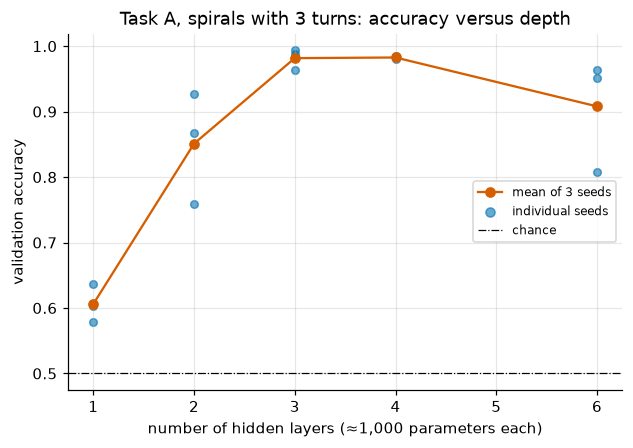

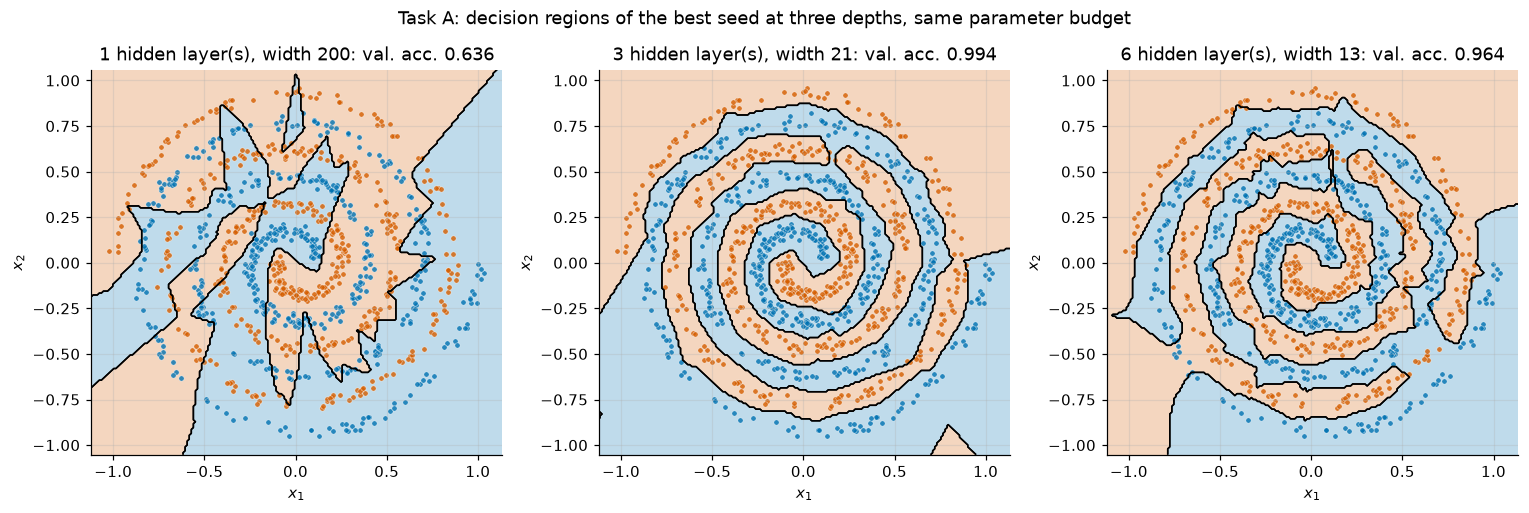

In [31]:
fig, ax1 = plt.subplots(figsize=(6.5, 4.2))
for depth in DEPTHS:
    accs = [results_A[depth, s][1] for s in SEEDS]
    ax1.scatter([depth] * 3, accs, color=COLORS[0], alpha=0.6, s=25)
means = [sum(results_A[d, s][1] for s in SEEDS) / 3 for d in DEPTHS]
ax1.plot(DEPTHS, means, "o-", color=COLORS[1], label="mean of 3 seeds")
ax1.scatter([], [], color=COLORS[0], alpha=0.6, label="individual seeds")
ax1.axhline(0.5, color="k", lw=0.8, ls="-.", label="chance")
ax1.set_xlabel("number of hidden layers (≈1,000 parameters each)")
ax1.set_ylabel("validation accuracy")
ax1.set_title("Task A, spirals with 3 turns: accuracy versus depth")
ax1.legend(fontsize=8)
plt.show()

show = [1, 3, 6]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, depth in zip(axes, show):
    best = max(SEEDS, key=lambda s: results_A[depth, s][1])
    m = models_A[depth, best][1]
    plot_decision_boundary(lambda P, m=m: m(P).argmax(1), XAv, yAv, ax=ax, padding=0.1,
                           title=f"{depth} hidden layer(s), width {width_for_budget(1000, 2, depth, 2)}: "
                                 f"val. acc. {results_A[depth, best][1]:.3f}")
fig.suptitle("Task A: decision regions of the best seed at three depths, same parameter budget")
plt.tight_layout()
plt.show()

On this task depth helps a great deal, then stops helping. With one hidden layer of 200 units, the network does not even fit the training set within the budget (training loss about 0.58), and its validation accuracy is 0.61, not far above chance (0.5). Its decision regions are jagged, star-shaped polygons that cut across the arms instead of following them. Two layers reach 0.85 on average, with a large spread. Three and four layers fit the training set essentially perfectly and reach 0.98 on the fresh sample; their regions follow the windings. At six layers (width 13), the mean drops to 0.91 and the seeds disagree more: two runs are close to depth 3–4, while one stops at training loss 0.24 and 0.81 accuracy. So, **for this task, budget and optimizer**, the best depth is in the middle.

Why might very deep, narrow plain MLPs underperform even though they could represent more? Each extra layer multiplies the backward signal by another Jacobian, a narrow ReLU layer can lose information when units die, and the loss surface becomes harder to navigate. Notebook 24 introduces the two standard remedies — **normalization layers** and **residual connections** — which make much deeper networks trainable. Without them, "deeper" is not automatically "better".

### Task B: the sawtooth from notebook 12

Notebook 12 built the 4-fold composition of the tent map, $T^{(4)}$, with 16 linear pieces, using **4 hidden layers of width 2** — 28 parameters — and proved that one hidden layer needs at least 15 units for it. Does gradient descent find such solutions? We train regression networks (MSE loss) on 1,024 equally spaced inputs. We feed the input rescaled to $[-1, 1]$, i.e. the network sees $u = 2x - 1$ and must output $T^{(4)}(x)$: with zero biases at initialization, every first-layer kink starts at $u = 0$, the middle of the interval, rather than at its edge. Budget: about 300 parameters (ten times what the construction needs), Adam with learning rate $10^{-2}$, 3,000 steps, 3 seeds.

Since $T^{(4)}$ maps a uniform input to a uniform output on $[0, 1]$, the target's variance is $1/12 \approx 0.0833$: predicting the constant $0.5$ scores exactly that. We report the **fraction of variance unexplained**, MSE / (1/12): 1 means "learned nothing", 0 means perfect.

In [32]:
def tent_k(x, k):
    """k-fold composition of the tent map T(x) = 2x for x < 1/2, 2 - 2x otherwise. x in [0, 1]."""
    for _ in range(k):
        x = torch.where(x < 0.5, 2 * x, 2 - 2 * x)
    return x


xB = torch.linspace(0, 1, 1024).unsqueeze(1)                 # (1024, 1)
uB, yB = 2 * xB - 1, tent_k(xB, 4)                           # network input in [-1, 1], target (1024, 1)

start = time.perf_counter()
results_B, models_B = {}, {}
for depth in DEPTHS:
    width = width_for_budget(300, 1, depth, 1)
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = mlp(1, width, depth, 1)
        mse = train_full_batch(model, uB, yB, loss_fn=F.mse_loss, steps=3000, lr=1e-2)
        results_B[depth, seed] = mse / (1 / 12)
        models_B[depth, seed] = model
print(f"15 runs in {time.perf_counter() - start:.0f} s\n")
print("depth  width  params   fraction of variance unexplained (3 seeds)   mean ± std")
for depth in DEPTHS:
    width = width_for_budget(300, 1, depth, 1)
    fv = torch.tensor([results_B[depth, s] for s in SEEDS])
    print(f"{depth:5d}  {width:5d}  {param_count(1, width, depth, 1):6d}   "
          + "  ".join(f"{v:.3f}" for v in fv.tolist()) + f"                        {fv.mean():.3f} ± {fv.std():.3f}")

15 runs in 16 s

depth  width  params   fraction of variance unexplained (3 seeds)   mean ± std
    1    100     301   0.542  0.610  0.579                        0.577 ± 0.034
    2     15     286   0.668  0.803  0.590                        0.687 ± 0.107
    3     11     298   0.413  0.513  0.505                        0.477 ± 0.055
    4      9     298   0.423  0.663  0.420                        0.502 ± 0.140
    6      7     302   0.549  0.803  0.179                        0.510 ± 0.314


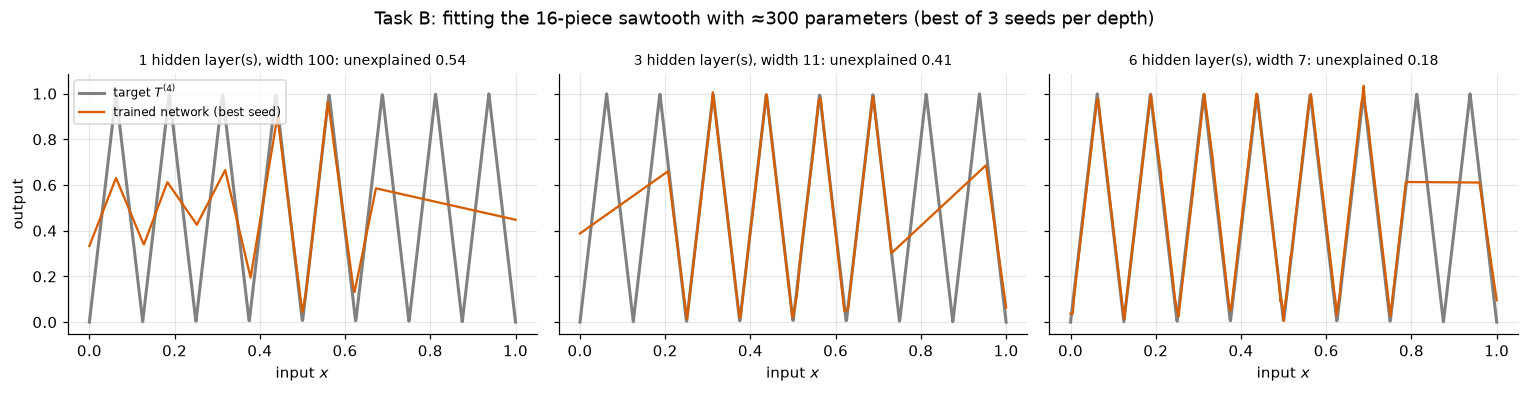

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, depth in zip(axes, [1, 3, 6]):
    best = min(SEEDS, key=lambda s: results_B[depth, s])
    with torch.no_grad():
        pred = models_B[depth, best](uB)
    ax.plot(xB, yB, color="gray", lw=2, label="target $T^{(4)}$")
    ax.plot(xB, pred, color=COLORS[1], label="trained network (best seed)")
    ax.set_xlabel("input $x$")
    ax.set_title(f"{depth} hidden layer(s), width {width_for_budget(300, 1, depth, 1)}: "
                 f"unexplained {results_B[depth, best]:.2f}", fontsize=9)
axes[0].set_ylabel("output")
axes[0].legend(fontsize=8)
fig.suptitle("Task B: fitting the 16-piece sawtooth with ≈300 parameters (best of 3 seeds per depth)")
plt.tight_layout()
plt.show()

Here the picture is very different from Task A, and from notebook 12's theory. No depth reliably learns the sawtooth with this budget. Most runs leave 40–80% of the variance unexplained. The means range from 0.48 (depth 3) to 0.69 (depth 2), and the spread across seeds (standard deviations of 0.03–0.31) is as large as the differences between depths. The single best run (depth 6, 0.18) comes from the depth with the largest spread; the other two depth-6 seeds reach only 0.55 and 0.80. The plots show *how* the networks fail. They reproduce some teeth essentially exactly and replace the rest with straight segments: the depth-6 run gets 12 of the 16 teeth, while the one-layer network matches a few teeth only roughly. The function that a 28-parameter deep network represents *exactly* is not what gradient descent finds in a 300-parameter one.

The lesson is the one notebook 12 ended on — **representing ≠ learning** — now measured: depth's representational advantage is only an advantage if the optimizer can reach the efficient solution. A run that has carved some teeth and bridged over others is stuck. Small changes to the weights cannot add a missing tooth without disturbing the existing ones, which is what a poor local solution looks like.

### What we can and cannot conclude

- **Empirical, for these setups only:** on many-turn spirals at ~1,000 parameters, 3–4 hidden layers beat 1 layer by a wide margin (0.98 against 0.61) and beat 6 layers on average; on the sawtooth at ~300 parameters, no depth succeeds reliably.
- With 3 seeds per configuration, a difference of a few points of accuracy is within the seed-to-seed spread and should not be read as real. Notebook 26 shows how to put confidence intervals on such comparisons.
- Different learning rates, step budgets, or normalization (notebook 24) could change the ranking, especially for the deepest nets. A fair comparison would tune each configuration's learning rate separately, at matched compute; we used one setting for all, which can favor some depths.

### Checkpoint 4.2

From `results_A`, compute `mean_acc_A`, a tensor of shape `(5,)` with the mean validation accuracy over the three seeds for each depth in `DEPTHS` (in that order), and `best_depth_A`, the depth with the highest mean (an `int`).

<details>
<summary><b>💡 Hint</b></summary>

`torch.tensor([[results_A[d, s][1] for s in SEEDS] for d in DEPTHS])` has shape `(5, 3)`; average over `dim=1`, then `DEPTHS[int(mean.argmax())]`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print("mean validation accuracy per depth:", [f"{a:.3f}" for a in mean_acc_A.tolist()], "  best depth:", best_depth_A)

In [ ]:
check_shape(mean_acc_A, (5,), "mean_acc_A")
_ref = torch.tensor([[results_A[d, s][1] for s in SEEDS] for d in DEPTHS], dtype=torch.float64).mean(1)
check_close(mean_acc_A.double(), _ref, "mean_acc_A")
check(best_depth_A == DEPTHS[int(_ref.argmax())], "best_depth_A should be the depth with the largest mean")
passed("Checkpoint 4.2")

## 5. Linear regions as a lens

A ReLU network is **piecewise linear**: wherever the on/off **activation pattern** of all its hidden units is fixed, the network is one affine map. Notebook 12 counted pieces in 1-D; in 2-D, the regions are polygons (Section 3). How many linear regions does a trained network actually use, and does depth multiply them as in the tent-map construction?

Counting regions in 2-D exactly is hard, so we count them **along a line segment** through the input space: we walk from point $\mathbf a$ to point $\mathbf b$ in 20,001 small steps, record the activation pattern at each point, and count how often it changes. Each change means the walk crossed a region boundary. (If two boundaries fall between consecutive points we count only one, so the result is a lower bound; with steps of about $10^{-4}$ this is rare.)

For **one hidden layer** with $H$ units, each unit's boundary is a straight line, which a segment crosses at most once, so a segment meets **at most $H + 1$ regions**. Deeper networks have bent boundaries that a segment can cross many times.

In [36]:
def activation_pattern(model, X):
    """Boolean (N, total hidden units): which ReLU units of an `mlp` are on at each row of X."""
    return torch.cat([h > 0 for h in capture(model, [m for m in model if isinstance(m, nn.ReLU)], X)], dim=1)


def regions_on_segment(model, a, b, n=20001):
    """Number of linear regions of a ReLU network met along the segment from a to b (lower bound)."""
    t = torch.linspace(0, 1, n).unsqueeze(1)                     # (n, 1)
    pattern = activation_pattern(model, a + t * (b - a))         # (n, units)
    return int((pattern[1:] != pattern[:-1]).any(dim=1).sum().item()) + 1


seg_a, seg_b = torch.tensor([-1.0, -0.6]), torch.tensor([1.0, 0.9])
print("depth  width  units   regions at init (3 seeds)   regions after training (3 seeds)   max for 1 layer")
regions = {}
for depth in DEPTHS:
    width = width_for_budget(1000, 2, depth, 2)
    r0 = [regions_on_segment(models_A[depth, s][0], seg_a, seg_b) for s in SEEDS]
    r1 = [regions_on_segment(models_A[depth, s][1], seg_a, seg_b) for s in SEEDS]
    regions[depth] = (r0, r1)
    print(f"{depth:5d}  {width:5d}  {depth * width:5d}   {str(r0):26s}  {str(r1):34s} "
          + (f"{width + 1}" if depth == 1 else ""))

depth  width  units   regions at init (3 seeds)   regions after training (3 seeds)   max for 1 layer
    1    200    200   [186, 188, 186]             [141, 152, 139]                    201
    2     29     58   [54, 44, 48]                [61, 71, 58]                       
    3     21     63   [71, 54, 56]                [81, 81, 73]                       
    4     17     68   [55, 84, 73]                [92, 73, 98]                       
    6     13     78   [50, 46, 110]               [129, 88, 113]                     


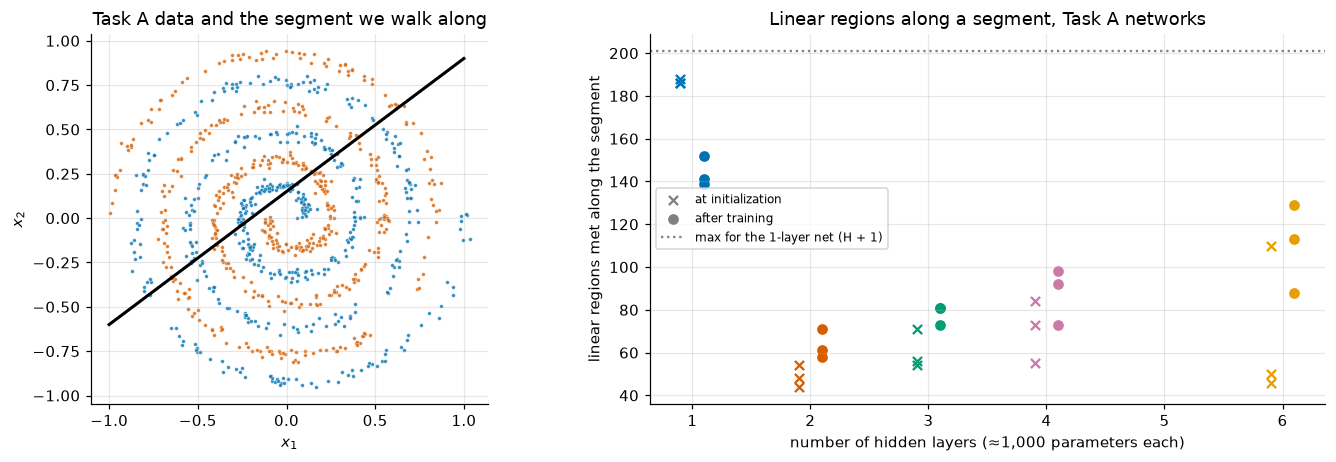

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
plot_dataset(XA, yA, ax=ax1, s=6, title="Task A data and the segment we walk along")
ax1.plot([seg_a[0], seg_b[0]], [seg_a[1], seg_b[1]], "k-", lw=2)
for depth, col in zip(DEPTHS, COLORS):
    r0, r1 = regions[depth]
    ax2.scatter([depth - 0.1] * 3, r0, marker="x", color=col)
    ax2.scatter([depth + 0.1] * 3, r1, marker="o", color=col)
ax2.scatter([], [], marker="x", color="gray", label="at initialization")
ax2.scatter([], [], marker="o", color="gray", label="after training")
ax2.axhline(width_for_budget(1000, 2, 1, 2) + 1, color="gray", ls=":", label="max for the 1-layer net (H + 1)")
ax2.set_xlabel("number of hidden layers (≈1,000 parameters each)")
ax2.set_ylabel("linear regions met along the segment")
ax2.set_title("Linear regions along a segment, Task A networks")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Three observations, for these networks and this segment:

- **At initialization**, the count is roughly of the order of the number of hidden units. The one-layer network (200 units) meets about 187 regions, close to its maximum of 201: with zero biases its 200 boundary lines all pass through the origin, so a segment that passes near the origin crosses almost all of them. The deeper networks (58–78 units) meet 44–110. The count does **not** grow like $2^L$: six layers did not beat two or three by any exponential factor. This is consistent with a result of Hanin and Rolnick (2019), stated here without proof: for randomly initialized ReLU networks, the expected number of regions met along a line scales with the total number of units, not exponentially with depth. The exponential counts of notebook 12 require carefully aligned weights that random initialization does not produce.
- **Training increases the count for the deeper networks**, on average at every depth (one depth-4 seed goes down, from 84 to 73); for example from about 49 to about 63 at depth 2, and to 88–129 at depth 6. It *decreases* it for the one-layer network (to 139–152). The deep networks add boundaries where the segment crosses the arms; the shallow one moves its lines away from where they were piled up at initialization.
- The trained deep networks use fewer pieces along this segment than the shallow one, yet classify far better. The shallow network's trouble in Task A is not a lack of pieces (it has the most) but that pieces bounded by straight lines that cross the whole plane cannot be arranged into six windings.

Linear-region counts are a useful lens on *what the network is doing*, but not a predictor of accuracy by themselves: more pieces is not the goal, pieces in the right places are.

### Checkpoint 5.1

Look at one trained network's output along the segment. For the depth-3, seed-0 model of Task A, compute `logit_gap`, the difference of logits $z_1 - z_0$ at the 20,001 points of the segment (shape `(20001,)`), and `n_sign_changes`, the number of times it changes sign — the number of times the segment crosses the **decision boundary**. Is it smaller or larger than the number of linear regions?

<details>
<summary><b>💡 Hint</b></summary>

`t = torch.linspace(0, 1, 20001).unsqueeze(1)`, points `seg_a + t * (seg_b - seg_a)`. Under `torch.no_grad()`: `z = model(points)`, `logit_gap = z[:, 1] - z[:, 0]`. Sign changes: `((logit_gap[1:] > 0) != (logit_gap[:-1] > 0)).sum()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"decision-boundary crossings: {n_sign_changes};  linear regions on the segment: {regions[3][1][0]}")

In [ ]:
check_shape(logit_gap, (20001,), "logit_gap")
with torch.no_grad():
    _zz = models_A[3, 0][1](seg_a + torch.linspace(0, 1, 20001).unsqueeze(1) * (seg_b - seg_a))
check_close(logit_gap, _zz[:, 1] - _zz[:, 0], "logit_gap", atol=1e-5)
check(n_sign_changes == int(((_zz[1:, 1] > _zz[1:, 0]) != (_zz[:-1, 1] > _zz[:-1, 0])).sum()), "n_sign_changes")
check(n_sign_changes < regions[3][1][0], "a sign change of an affine piece needs a region, so there are fewer crossings than regions")
passed("Checkpoint 5.1")

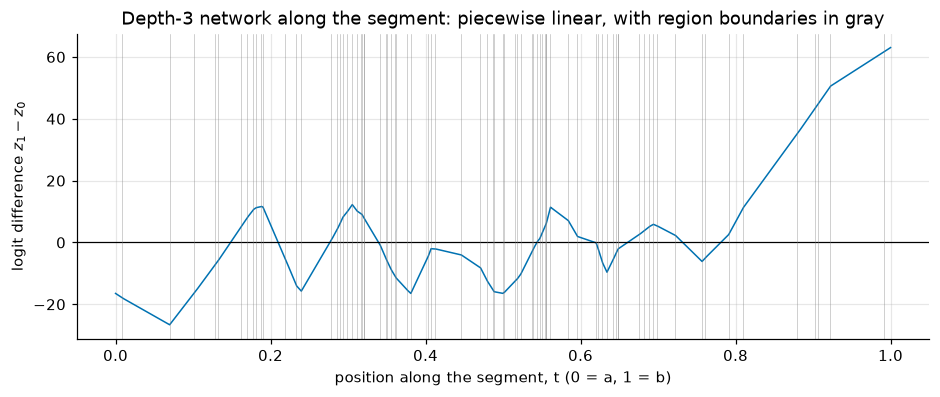

In [40]:
fig, ax = plt.subplots(figsize=(10, 3.6))
tt = torch.linspace(0, 1, 20001)
with torch.no_grad():
    z_seg = models_A[3, 0][1](seg_a + tt.unsqueeze(1) * (seg_b - seg_a))      # (20001, 2)
ax.plot(tt, z_seg[:, 1] - z_seg[:, 0], color=COLORS[0], lw=1)
ax.axhline(0, color="k", lw=0.8)
pat = activation_pattern(models_A[3, 0][1], seg_a + tt.unsqueeze(1) * (seg_b - seg_a))
change = torch.nonzero((pat[1:] != pat[:-1]).any(dim=1)).squeeze(1)
for i in change.tolist():
    ax.axvline(tt[i].item(), color="gray", lw=0.4, alpha=0.6)
ax.set_xlabel("position along the segment, t (0 = a, 1 = b)")
ax.set_ylabel("logit difference $z_1 - z_0$")
ax.set_title("Depth-3 network along the segment: piecewise linear, with region boundaries in gray")
plt.show()

The curve is made of straight pieces that change slope only at the gray lines (the region boundaries), exactly as a piecewise-linear function should. It crosses zero 9 times, against 81 pieces. Many regions exist to shape the logit (how confident the network is), not to move the decision boundary. Some gray lines show no visible kink at all: a unit can switch on or off with an outgoing weight so small that the slope barely changes.

## Exercises

### Exercise 1 (modify): what the blocks do to other data, with other units

The cell below trains a `bottleneck_net` and plots its 2-D representations, with each stage's validation probe accuracy in the panel title. Run it as given (spirals, tanh, 4 blocks). Then change, one at a time:

1. `DATASET = "rings"`;
2. `ACT = nn.ReLU` (with spirals);
3. `N_BLOCKS = 2` and then `N_BLOCKS = 6` (spirals, tanh).

For each, describe how the representations change from stage to stage, at which stage the classes become linearly separable, and anything that looks qualitatively different (folding, collapsing onto a line, points piling up). Relate the ReLU case to Section 3: what does a ReLU block do to the plane that a tanh block cannot?

<details>
<summary><b>💡 Hint</b></summary>

A tanh block is smooth: it bends and can fold the plane, but without corners. A ReLU block is exactly zero on half-planes of its hidden units, so it can **flatten** whole regions onto a line or a point, with sharp creases. For the rings, ask whether *one* block already suffices. Watch the probe numbers in the panel titles and the printed training loss, not only the pictures: a training loss near $\ln 2 \approx 0.69$ means the network still predicts 50/50 everywhere.

</details>

spirals, Tanh, 4 blocks: training loss 0.0304, validation accuracy 0.960


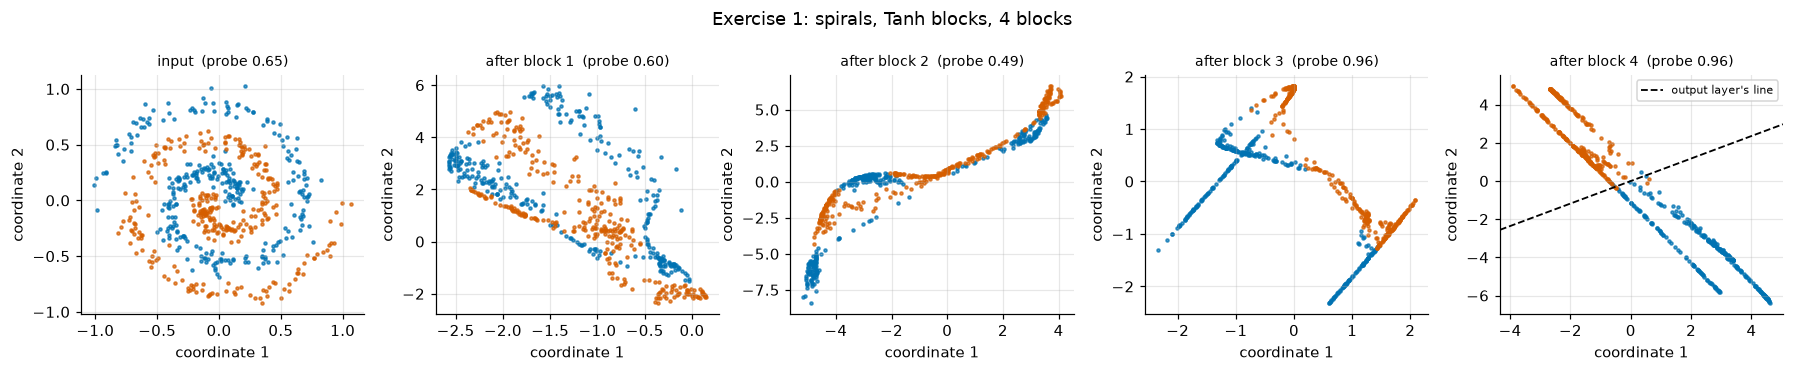

In [41]:
DATASET = "spirals"     # "spirals" or "rings"
ACT = nn.Tanh           # nn.Tanh or nn.ReLU
N_BLOCKS = 4

make = {"spirals": lambda s: make_spirals(n=300, classes=2, seed=s), "rings": lambda s: make_rings(n=300, seed=s)}[DATASET]
Xe, ye = make(0)
Xev, yev = make(1)
torch.manual_seed(0)
net_e = bottleneck_net(n_blocks=N_BLOCKS, act=ACT)
loss_e = train_full_batch(net_e, Xe, ye, steps=2000, lr=0.01)
probes_e = probe_all_layers(net_e, bottleneck_reps, Xe, ye, Xev, yev, 2)
print(f"{DATASET}, {ACT.__name__}, {N_BLOCKS} blocks: training loss {loss_e:.4f}, validation accuracy {accuracy(net_e, Xev, yev):.3f}")
plot_reps(bottleneck_reps(net_e, Xe), ye, head=net_e[-1],
          titles=[("input" if j == 0 else f"after block {j}") + f"  (probe {p:.2f})" for j, p in enumerate(probes_e)],
          suptitle=f"Exercise 1: {DATASET}, {ACT.__name__} blocks, {N_BLOCKS} blocks")

*Your answer:*

### Exercise 2 (implement): PCA from the covariance matrix

Section 2 computed PCA with the SVD of the centered data. An equivalent route goes through the **covariance matrix** $C = \frac{1}{N} H_c^\top H_c$ (shape $(d, d)$): since $H_c = U S V^\top$, we get $C = V \frac{S^2}{N} V^\top$, so the principal directions are the eigenvectors of $C$ and the eigenvalues $\lambda_k = s_k^2/N$ are the variances along them.

Implement `pca_2d_cov(H)` with `torch.linalg.eigh`, returning `(coords, ratio)` exactly like `pca_2d`: coordinates of shape `(N, 2)` on the top two principal directions, and their explained-variance ratios of shape `(2,)`. Note that `eigh` returns eigenvalues in **ascending** order. Principal directions are defined only up to sign, so the check compares coordinates up to the sign of each column.

<details>
<summary><b>💡 Hint</b></summary>

`Hc = H - H.mean(0, keepdim=True)`, `C = Hc.T @ Hc / H.shape[0]`, `evals, evecs = torch.linalg.eigh(C)`. The two largest are the last two: `top = evecs[:, [-1, -2]]` (columns), `coords = Hc @ top`, `ratio = evals[[-1, -2]] / evals.sum()`.

</details>

In [ ]:
def pca_2d_cov(H):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
def _match_up_to_sign(a, b, name):
    signs = torch.sign((a * b).sum(dim=0))            # (2,) +1 or -1 per column
    check_close(a * signs, b, name, rtol=1e-4, atol=1e-4)


_H = torch.randn(500, 6, generator=torch.Generator().manual_seed(0), dtype=torch.float64) @ torch.diag(
    torch.tensor([5.0, 3.0, 1.0, 0.5, 0.2, 0.1], dtype=torch.float64))
_c, _r = pca_2d_cov(_H)
check_shape(_c, (500, 2), "coords")
check_shape(_r, (2,), "ratio")
_c_ref, _r_ref = pca_2d(_H)
_match_up_to_sign(_c, _c_ref, "coords versus the SVD version")
check_close(_r, _r_ref, "ratio versus the SVD version", rtol=1e-6)
_U, _S, _V = torch.pca_lowrank(_H, q=2, center=True, niter=6)
_match_up_to_sign(_c, (_H - _H.mean(0)) @ _V, "coords versus torch.pca_lowrank")
_c4, _r4 = pca_2d_cov(reps_w[4].double())
check_close(_r4, pca_2d(reps_w[4].double())[1], "ratio on the trained network's H^(4)", rtol=1e-6)
# Edge case: points on a line in R^3 (rank 1 after centering). All variance is in PC1; PC2 has none.
_t = torch.linspace(-1, 1, 7, dtype=torch.float64).unsqueeze(1)
_line = 5.0 + _t * torch.tensor([[1.0, 2.0, -2.0]], dtype=torch.float64)       # (7, 3)
_cl, _rl = pca_2d_cov(_line)
check_close(_rl, torch.tensor([1.0, 0.0], dtype=torch.float64), "ratio for collinear points", atol=1e-9)
check_close(_cl[:, 0].abs(), (_t.squeeze(1) * 3).abs(), "PC1 coordinate = signed distance along the line (|direction| = 3)")
check_close(_cl[:, 1], torch.zeros(7, dtype=torch.float64), "PC2 coordinates of collinear points", atol=1e-9)
passed("Exercise 2")

Which route is better in practice? Forming $C$ squares the singular values, so tiny ones lose relative precision in `float32` (the condition number is squared); the SVD route avoids that. For $N \gg d$, $C$ is small ($d \times d$) and cheap. `torch.pca_lowrank` uses a randomized algorithm that is fast for very large matrices when only a few components are needed.

### Exercise 3 (debug): recorded pre-activations that are never negative

`record_preactivations(model, X)` is supposed to return the pre-activations $A^{(\ell)}$ of every hidden layer: the outputs of every `nn.Linear` except the last. A colleague uses it on a model built with `nn.ReLU(inplace=True)` (a common memory-saving option) and finds that the recorded "pre-activations" contain **no negative numbers at all**, so they conclude that no unit is ever below its threshold. The hook is in the comments; find the bug and fix it inside the solution markers.

<details>
<summary><b>💡 Hint</b></summary>

What does `inplace=True` do to the tensor that `nn.Linear` returned, and what exactly did the hook store — the values, or a reference to that tensor? Notebook 15 used `clone()` for the same reason with `state_dict` snapshots.

</details>

The check is written as a function so that the same test can be run on any recorder, including the original buggy one. It compares the recorded tensors with $A^{(\ell)}$ computed by hand, on a model with in-place ReLUs, and with a deterministic edge case: a batch of a single example, and an input of all zeros, for which $A^{(1)} = \mathbf b^{(1)}$ exactly.

In [44]:
def check_recorder(recorder):
    """Test a pre-activation recorder against hand-computed A^(1), A^(2) on a model with in-place ReLUs."""
    torch.manual_seed(3)
    net = nn.Sequential(nn.Linear(2, 6), nn.ReLU(inplace=True), nn.Linear(6, 6), nn.ReLU(inplace=True), nn.Linear(6, 2))
    for X in [torch.randn(50, 2), torch.zeros(1, 2)]:
        rec = recorder(net, X)
        with torch.no_grad():
            A1 = net[0](X)
            A2 = net[2](torch.relu(A1))
        check(len(rec) == 2, "one record per hidden layer")
        check_close(rec[0], A1, f"A^(1) for a batch of shape {tuple(X.shape)}")
        check_close(rec[1], A2, f"A^(2) for a batch of shape {tuple(X.shape)}")
        check(all(r.grad_fn is None for r in rec), "records should be detached")
    check(bool((recorder(net, torch.randn(50, 2))[0] < 0).any()), "pre-activations should include negative values")

In [ ]:
def record_preactivations(model, X):
    """Outputs of every nn.Linear except the last, as a list of (N, width) tensors."""
    records = []
    linears = [m for m in model if isinstance(m, nn.Linear)][:-1]

    def hook(module, inputs, output):
        # Buggy version:
        #     records.append(output)
        # YOUR CODE HERE
        raise NotImplementedError

    handles = [m.register_forward_hook(hook) for m in linears]
    try:
        with torch.no_grad():
            model(X)
    finally:
        for h in handles:
            h.remove()
    return records

In [ ]:
check_recorder(record_preactivations)
passed("Exercise 3")

The same check applied to the original, buggy hook (kept here as a teaching copy) fails, as it should:

In [47]:
def record_preactivations_buggy(model, X):
    records = []
    linears = [m for m in model if isinstance(m, nn.Linear)][:-1]
    handles = [m.register_forward_hook(lambda module, inputs, output: records.append(output)) for m in linears]
    try:
        with torch.no_grad():
            model(X)
    finally:
        for h in handles:
            h.remove()
    return records


try:
    check_recorder(record_preactivations_buggy)
    print("the buggy version unexpectedly passed")
except AssertionError as err:
    print("buggy version fails the check:", err)

buggy version fails the check: A^(1) for a batch of shape (50, 2) differs from the expected value (max abs difference 2.44)


### Exercise 4 (investigate): which depth for which checkerboard?

Section 4 found that the best depth depends on the task. Investigate this on the checkerboard, whose difficulty you can dial with the number of tiles. This time **you write the experiment**: the training loop over configurations and seeds, the aggregation, and the plot.

**Question.** At a fixed parameter budget, how does the best number of hidden layers depend on how fine the checkerboard is?

**Contract** (the check re-runs one configuration independently, so follow it exactly):

- Tiles $\in$ `TILES = [2, 4, 6]`, depths $L \in$ `DEPTHS_CB = [1, 2, 3, 4]`, seeds `SEEDS = [0, 1, 2]`, budget `BUDGET_CB = 600` parameters.
- Data for each number of tiles: training set `make_checkerboard(n=1000, tiles=tiles, seed=0)`, validation set `make_checkerboard(n=2000, tiles=tiles, seed=1)`.
- Model for each (tiles, depth, seed): `width = width_for_budget(BUDGET_CB, 2, depth, 2)`, then `torch.manual_seed(seed)` immediately followed by `model = mlp(2, width, depth, 2)`, then `train_full_batch(model, X, y, steps=1500, lr=3e-3)`.
- Metric: validation accuracy, `accuracy(model, X_val, y_val)`.
- Store the results in a dict `results_cb` with keys `(tiles, depth, seed)` and float values; then `mean_cb` and `std_cb`, tensors of shape `(3, 4)` (rows: tiles in the order of `TILES`; columns: depths in the order of `DEPTHS_CB`) holding the mean and the standard deviation (`torch.std`, the default) over seeds.
- Plot validation accuracy against depth, one line of means per number of tiles, with the individual seeds as dots.

The 36 runs take about half a minute on a laptop CPU.

**Before running**, write down your prediction in the cell below: for each number of tiles, which depth will win, and by roughly how much? Justify it from Sections 3–5. Then answer, in the conclusion cell:

1. For each number of tiles, which depth works best, and is the difference larger than the spread across seeds?
2. How does the advantage of depth change as the checkerboard gets finer? Explain with what Sections 3 and 5 showed about how units compose regions.
3. Where was your prediction right or wrong? Name at least one way the conclusion could change in a different setup (budget, steps, learning rate, data size), and the follow-up experiment that would test it.

Your written answer is judged on this rubric, which the code check does not grade: a prediction made before running; the controls used (here the one-hidden-layer baseline at the same budget, and chance accuracy 0.5); quantitative evidence across seeds, with the spread; an honest account of where the prediction failed; limitations; and a concrete follow-up.

*Your prediction (before running):*

<details>
<summary><b>💡 Hint</b></summary>

Two nested loops: the outer one over `TILES` creates the two datasets once, the inner ones over `DEPTHS_CB` and `SEEDS` build, train and evaluate a model. Copy the structure of the Task A loop in Section 4. For the aggregation, `torch.tensor([[[results_cb[t, d, s] for s in SEEDS] for d in DEPTHS_CB] for t in TILES])` has shape `(3, 4, 3)`; take `.mean(dim=2)` and `.std(dim=2)`. For the plot, one `ax.plot(DEPTHS_CB, mean_cb[i], "o-")` per row and `ax.scatter` for the seeds.

</details>

In [ ]:
TILES = [2, 4, 6]
DEPTHS_CB = [1, 2, 3, 4]
BUDGET_CB = 600

# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(results_cb, dict), "results_cb should be a dict")
_missing = [(t, d, s) for t in [2, 4, 6] for d in [1, 2, 3, 4] for s in [0, 1, 2] if (t, d, s) not in results_cb]
check(not _missing, f"results_cb is missing keys, e.g. {_missing[:3]}")
check(all(0.0 <= float(v) <= 1.0 for v in results_cb.values()), "accuracies must lie in [0, 1]")
check_shape(mean_cb, (3, 4), "mean_cb")
check_shape(std_cb, (3, 4), "std_cb")
_tab = torch.tensor([[[float(results_cb[t, d, s]) for s in [0, 1, 2]] for d in [1, 2, 3, 4]] for t in [2, 4, 6]],
                    dtype=torch.float64)
check_close(mean_cb.double(), _tab.mean(2), "mean_cb (rows: tiles, columns: depths)")
check_close(std_cb.double(), _tab.std(2), "std_cb (rows: tiles, columns: depths)")
# Independent re-run of one configuration from the contract.
_Xc, _yc = make_checkerboard(n=1000, tiles=4, seed=0)
_Xcv, _ycv = make_checkerboard(n=2000, tiles=4, seed=1)
torch.manual_seed(1)
_m = mlp(2, width_for_budget(600, 2, 2, 2), 2, 2)
train_full_batch(_m, _Xc, _yc, steps=1500, lr=3e-3)
check_close(float(results_cb[4, 2, 1]), accuracy(_m, _Xcv, _ycv), "results_cb[4, 2, 1] versus an independent re-run", atol=1e-6)
passed("Exercise 4 (code; the written conclusion is graded with the rubric)")

*Your conclusion:*

## Summary and what's next

- Hidden layers compute **representations**: each layer re-describes the data, and training chooses re-descriptions that make the final linear readout work. With 2-D bottleneck blocks we watched a smooth network deform the plane until two spiral arms lay on opposite sides of a line; the output layer is just a linear classifier on the last representation. Intermediate stages need not be more separable than earlier ones (the bottleneck probe dipped to chance after block 2).
- **Forward hooks** record any layer's output; store `output.detach().clone()`, or in-place operations and the autograd graph will bite (Exercise 3).
- **PCA** (center, SVD, keep the top two right singular vectors) gives the best 2-D linear view of a wide layer, with explained-variance ratios $s_k^2/\sum_j s_j^2$; we verified that no random projection keeps more variance. It can hide structure in the discarded dimensions.
- **Linear probes** measure how linearly decodable the label is at each layer. In the trained 4×32 network, probe accuracy rose from 0.46 at the input to 0.94 at the last hidden layer, about the network's own accuracy, while the untrained control stayed at or below the input's level. A linear map cannot increase linear separability; the gains happen at the nonlinearities.
- **Units are feature detectors**: first-layer ReLUs detect half-planes; second-layer units combine them into bounded polygonal patches, a graded version of notebook 11's polygons.
- **Width versus depth, at matched parameters, budget and initialization, over 3 seeds:** on many-turn spirals (and, in Exercise 4, fine checkerboards), 2–4 hidden layers clearly beat one wide layer, and 6 layers were less reliable; on the sawtooth, where theory says depth is exponentially better, no depth learned reliably. These are empirical results for these setups, not laws.
- **Linear regions** along a line: at initialization their number was of the order of the number of units, not exponential in depth (consistent with Hanin and Rolnick, 2019). Training added regions to the deep networks and removed some from the shallow one; the count alone did not predict accuracy.

This completes Chapter 3. We built MLPs from raw tensors, derived backpropagation, took `nn.Module` apart, and studied each design choice — activation, loss, initialization, optimizer, depth. But every experiment so far ran on small synthetic datasets, held entirely in memory, with ad hoc validation samples and three seeds. **Chapter 4 — Training models reliably** makes this systematic: data pipelines with `Dataset` and `DataLoader` (notebook 21); generalization, splits and overfitting (22); regularization, including dropout (23); **normalization layers and residual connections** (24), which fix the trainability problems of deep plain MLPs we just saw; evaluation beyond accuracy (25); rigorous multi-seed experiments with confidence intervals (26); and a reusable, checkpointed training system (27).